# Imports

In [1]:
import sys
from pathlib import Path
sys.path.append("../src")

import numpy as np
from evaluate import (
    load_model_and_classes, load_test_set, load_history,
    plot_learning_curves, get_predictions, print_report,
    plot_confusion_matrix, print_medical_summary,
    show_examples, save_metrics,
)

MODEL_PATH   = "../models/best_brainscan.keras"
CLASSES_PATH = "../models/class_names.json"
HISTORY_PATH = "../models/training_history.json"
DATA_PATH    = "../data/processed/brainscan_data.npz"
REPORTS_DIR  = Path("../reports")
REPORTS_DIR.mkdir(exist_ok=True)

print("Setup OK")

Setup OK


# Load model, classes and test data

In [3]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.16.2
Keras: 3.12.4


In [5]:
model, class_names = load_model_and_classes(MODEL_PATH, CLASSES_PATH)
X_test, y_test = load_test_set(DATA_PATH)


Model loaded: ../models/best_brainscan.keras
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Test images: (1405, 224, 224, 3)
Pixel range: 0.0 to 1.0


# Learning curves

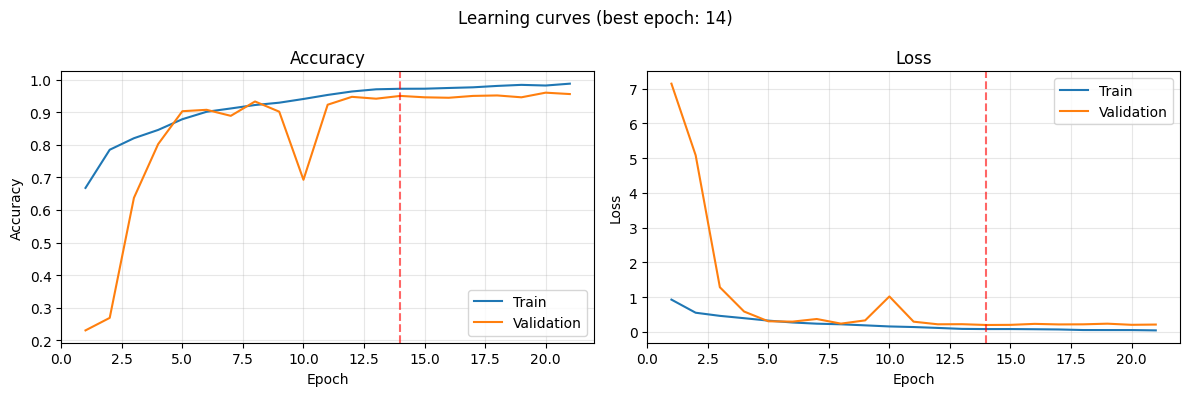

In [6]:
history = load_history(HISTORY_PATH)
plot_learning_curves(history, save_path=REPORTS_DIR / "learning_curves.png")


In [7]:
probabilities, y_pred, y_true = get_predictions(model, X_test, y_test)

print("Predictions:", probabilities.shape)
print("Example probabilities:", np.round(probabilities[0], 4))


Predictions: (1405, 4)
Example probabilities: [0.0142 0.9858 0.     0.    ]


#  Metrics report

In [8]:
accuracy = print_report(y_true, y_pred, probabilities, class_names)



TEST SET RESULTS
Accuracy: 0.9537  (95.37%)
Samples : 1405
-------------------------------------------------------
              precision    recall  f1-score   support

      glioma     0.9612    0.9167    0.9384       324
  meningioma     0.9021    0.9240    0.9129       329
     notumor     0.9705    0.9875    0.9789       400
   pituitary     0.9773    0.9773    0.9773       352

    accuracy                         0.9537      1405
   macro avg     0.9528    0.9514    0.9519      1405
weighted avg     0.9540    0.9537    0.9537      1405



# confusion Metrix

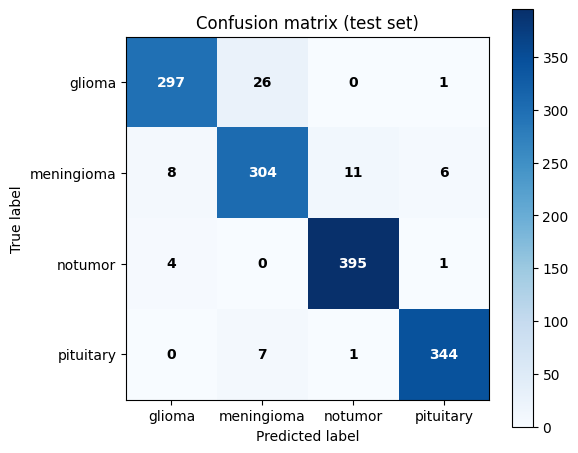

Medical summary is only available for 2 classes.


In [10]:
matrix = plot_confusion_matrix(
    y_true, y_pred, class_names,
    save_path=REPORTS_DIR / "confusion_matrix.png"
)

# Find the index of the "tumor" class automatically
tumor_index = next(
    (i for i, name in enumerate(class_names)
     if name.lower() in ("yes", "tumor", "cancer")),
    1,
)

print_medical_summary(matrix, class_names, positive_index=tumor_index)



# Correct predictions

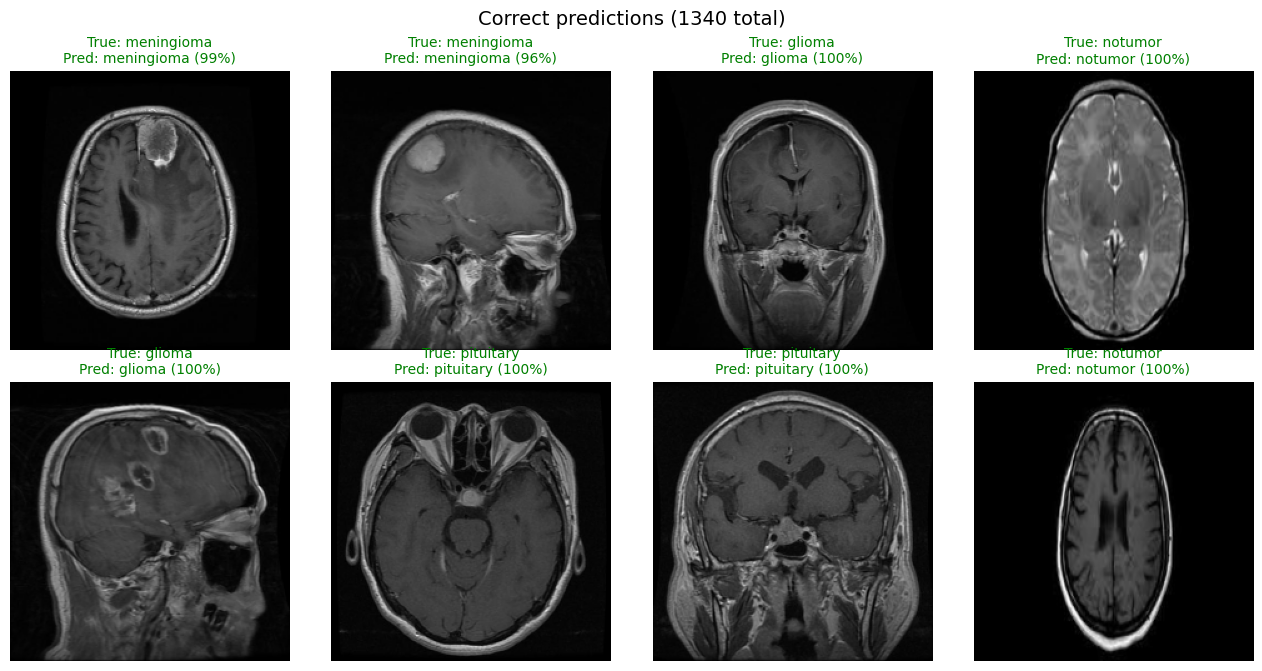

In [11]:
show_examples(
    X_test, y_true, y_pred, probabilities, class_names,
    correct=True, num_images=8,
    save_path=REPORTS_DIR / "correct_predictions.png"
)

# Incorrect predictions (the important ones)

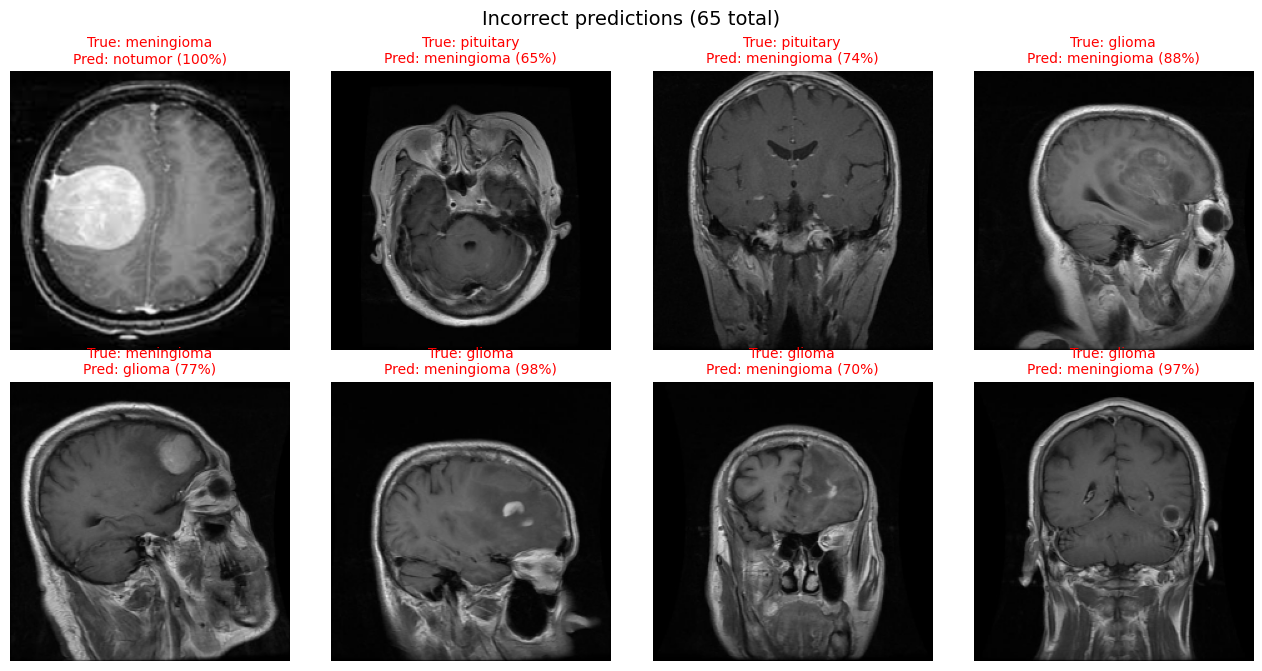

In [12]:
show_examples(
    X_test, y_true, y_pred, probabilities, class_names,
    correct=False, num_images=8,
    save_path=REPORTS_DIR / "wrong_predictions.png"
)


# save metrics to json

In [13]:
save_metrics(
    y_true, y_pred, class_names, accuracy, matrix,
    save_path=REPORTS_DIR / "test_metrics.json"
)

Metrics saved to: ..\reports\test_metrics.json
